# Clasificación de Datos

### Carga de datos

In [34]:
df_biare = pd.read_csv("../Limpieza de datos (Practica 1)/biare_limpio_2021_2024.csv")

### Importar librerías

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

### Agrupamos nuestros valores para poder dividir en tres niveles educativos

Agrupamos nuestras respuestas para dividir en nivel de educacion basico, medio y superior

In [36]:
#vemos el total de respuestas
df_biare['cs_I_NIV'].value_counts()

cs_I_NIV
Profesional                    2258
Secundaria                     1819
Preparatoria o bachillerato    1692
Primaria                       1184
Carrera técnica                 508
Maestría                        229
Ninguno                         187
Normal                           63
Doctorado                        56
No sabe                          21
Preescolar                        2
Name: count, dtype: int64

In [37]:
#vemos en que categoria quedara cada una de las respuestas
niveles = {
    'Ninguno': 'Básica', 'Preescolar': 'Básica', 'Primaria': 'Básica', 'Secundaria': 'Básica',
    'Preparatoria o bachillerato': 'Media', 'Carrera técnica': 'Media', 'Normal': 'Media',
    'Profesional': 'Superior', 'Maestría': 'Superior', 'Doctorado': 'Superior'
}

#creamos una nueva columna con los niveles educativos
df_biare['nivel_edu'] = df_biare['cs_I_NIV'].map(niveles)

#vemos la distribucion de nuestra categoria
print(df_biare['nivel_edu'].value_counts(dropna=False))
print(df_biare['nivel_edu'].value_counts(normalize=True, dropna=False).round(3))

nivel_edu
Básica      3192
Superior    2543
Media       2263
NaN           21
Name: count, dtype: int64
nivel_edu
Básica      0.398
Superior    0.317
Media       0.282
NaN         0.003
Name: proportion, dtype: float64


### Separamos nuestras demás variables de nuestra variable objetivo

In [38]:
#una lista con nuestras variables que nos ayudaran a predecir el nivel educativo
predictores_edu = ['cs_EDA', 'cb_P1', 'cb_P5_1', 'cb_P5_2', 'cb_P5_6',
                   'cb_P5_7', 'cb_P5_8', 'cb_P5_9', 'cb_P3_3', 'cb_P3_9']

#creamos un dataframe con las variables predictoras y la variable objetivo quitando nulos
datos_edu = df_biare[predictores_edu + ['nivel_edu']].dropna()

#separamos las variables que predicen y la variable objetivo
X_edu = datos_edu[predictores_edu]
y_edu = datos_edu['nivel_edu']


### Separamos los datos de entrenamiento de los de prueba

separamos los datos de entrenamiento de los de prueba, el 80% delos datos serviran para entrenar mientras que el 20% serán para predecir, el random state asegura que los resultados sean los mismo minetras que stratify se asegura que se tenga el mismo porcentaje de nivel de educacion

In [39]:
X_train_edu, X_test_edu, y_train_edu, y_test_edu = train_test_split(X_edu, y_edu, test_size=0.2, random_state=42, stratify=y_edu)


### Escalamos los datos para que su distancia sea normalizada

se escalan los datos para que las distancias que se miden tengan la misma escala, es una normalizacion que nos indica a cuantas desviaciones estandar se encuentran los vecinos mas cercanos

In [40]:
#usamos standarscaler para ver que tan lejos o que tan cerca esta del promedio
escala = StandardScaler()

#escalamos los datos de entrenamiento y prueba
X_train_edu_esc = escala.fit_transform(X_train_edu)
X_test_edu_esc = escala.transform(X_test_edu)

### Hacemos pruebas con k para saber cuantos vecinos visitar

k representa el número de vecinos que nuestro knn debe consultar para asignarle una categoría

In [47]:
#la lista con el nuumero de vecinos que debe visitar, del 1 a 52, va de uno en uno para el for
valores_k = range(1, 52, 1)
#resultados
exactitudes_cv = []

#for para ver el resultado de cada numero
for k in valores_k:
    #se  hace yb modelo knn que visitara los k valores que tenemos en la lista, el entrenamiento se divide en 5 partes
    #una parte se usa para prueba y las otras 4 para entrenamiento y al final se le da un score.
    puntajes = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_edu_esc, y_train_edu, cv=5)
    #se promedian los valores de las 5 partes y se obtiene un valor final
    exactitudes_cv.append(puntajes.mean())

#vemos cual es el valor de k que nos da el mejor resultado
mejor_k = list(valores_k)[int(np.argmax(exactitudes_cv))]
print(f"k que mas nos sirve: {mejor_k}")

k que mas nos sirve: 46


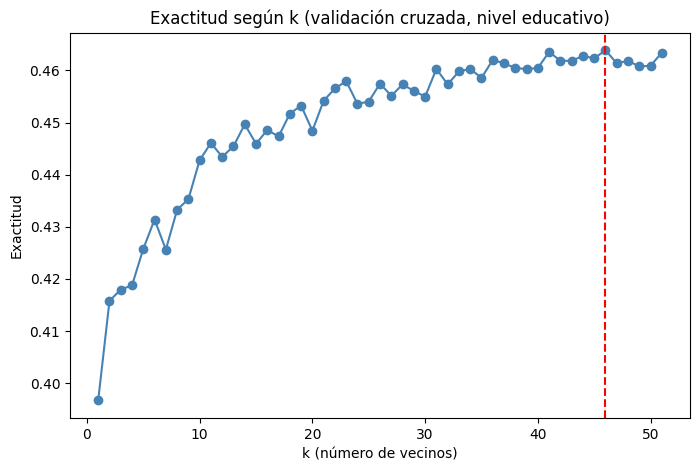

In [48]:
plt.figure(figsize=(8, 5))
plt.plot(valores_k, exactitudes_cv, marker='o', color='steelblue')
plt.axvline(mejor_k, color='red', linestyle='--')
plt.title('Exactitud según k (validación cruzada, nivel educativo)')
plt.xlabel('k (número de vecinos)')
plt.ylabel('Exactitud')
plt.show()